# 7장 일반화 좌표를 이용한 동적 추론 (실습)

6장의 캡슐에 일반화 좌표를 더한다(버전 0.2). 이제 물이 움직이고 Hydar 는 해류에 실려 목표 깊이 v 로 다가간다. 캡슐은 깊이뿐 아니라 속도, 가속도까지 μ̃x = [μ, μ′, μ″, μ′′′] 로 추론한다.

1. 생성 과정: 운동 방정식 x′ = −x + v 와 감각 사상의 고차 도함수
2. 일반화 정밀도: 매끄러움 s² 가 고차 오차의 무게를 어떻게 정하는가
3. 일반화 감각을 만드는 세 방법(확장, 정확, 후진 차분)
4. 정적 비교: p = 0, 1, 2, 3
5. 움직이는 세계: 사전이 목표일 때와 출발점일 때
6. 유색 잡음 속 추적

마지막으로 잡음의 매끄러움을 잘못 짐작하면 무엇이 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 5.0
t = np.arange(0, T + dt / 2, dt)
N = t.size
print("시간 점", N, "개, 간격", dt)

시간 점 1001 개, 간격 0.005


## 1. 생성 과정

운동 방정식 x′ = f_gp(x, v) = a x + v (a = −1). x 가 v 보다 작으면 깊어지고 크면 얕아져, Hydar 는 해류에 실려 깊이 v 로 다가간다. 감각 사상은 6장과 같은 시그모이드이고, 일반화 감각을 정확히 계산하려면 g 의 3 차 도함수까지 필요하다.

In [2]:
a = -1.0

def f_gp(x, v):  return a * x + v
def df_gp(x, v): return a

def _e(x): return np.exp(5 - x / 5)

def g_gp(x):    return 25 - 16 / (1 + _e(x))
def dg_gp(x):   return -16 / 5 * _e(x) / (1 + _e(x))**2
def ddg_gp(x):  e = _e(x); return -16 / 25 * e * (e - 1) / (1 + e)**3
def dddg_gp(x): e = _e(x); return -16 / 125 * e * (e**2 - 4 * e + 1) / (1 + e)**4

# 수치 미분으로 해석 도함수를 확인한다
h, x0 = 1e-3, 30.0
num = [(g_gp(x0 + h) - g_gp(x0 - h)) / (2 * h),
       (dg_gp(x0 + h) - dg_gp(x0 - h)) / (2 * h),
       (ddg_gp(x0 + h) - ddg_gp(x0 - h)) / (2 * h)]
for k, (fa, fn) in enumerate(zip([dg_gp(x0), ddg_gp(x0), dddg_gp(x0)], num), 1):
    print(f"g 의 {k}차 도함수 (x=30):  해석 {fa:+.6f}   수치 {fn:+.6f}")

g 의 1차 도함수 (x=30):  해석 -0.629158   수치 -0.629158
g 의 2차 도함수 (x=30):  해석 +0.058149   수치 +0.058149
g 의 3차 도함수 (x=30):  해석 +0.004522   수치 +0.004522


## 2. 일반화 좌표의 도구 — D 와 일반화 정밀도

derivativeD 는 벡터를 한 칸씩 위로 미는 행렬이다. temporalC 는 매끄러움 s² 인 가우스 잡음의 시간 공분산 S 이고, 일반화 정밀도는 Π̃ = (S ⊗ Σ)⁻¹ 다(2장). 대각 원소를 위치 기준 백분율로 보면 고차 오차가 얼마나 무겁게 들어가는지 알 수 있다.

In [3]:
def derivativeD(p):
    """일반화 좌표의 미분 연산자: [x, x′, x″, …] 를 [x′, x″, …, 0] 으로 민다."""
    return np.eye(p + 1, k=1)

def temporalC(p, s2):
    """매끄러움 s2 인 잡음의 (p+1)×(p+1) 시간 공분산 행렬."""
    q = np.arange(p + 1)
    r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]])
        r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print("D (p=3) =\n", derivativeD(3).astype(int))
print()
print("매끄러움 s²     위치    속도       가속도      저크   (Π̃ 대각, 위치 = 100 %)")
for name, s2 in [("1/64 (매끄러움)", 1 / 64), ("1/2000", 1 / 2000), ("1e-5 (백색)", 1e-5)]:
    d = np.diag(inv(temporalC(3, s2)))
    print(f"{name:16s}", "  ".join(f"{100 * v / d[0]:9.3g}%" for v in d))

D (p=3) =
 [[0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [0 0 0 0]]

매끄러움 s²     위치    속도       가속도      저크   (Π̃ 대각, 위치 = 100 %)
1/64 (매끄러움)            100%       5.21%     0.0326%   0.000339%
1/2000                 100%      0.167%   3.33e-05%   1.11e-08%
1e-5 (백색)              100%    0.00333%   1.33e-08%   8.89e-14%


## 3. 일반화 감각을 만드는 세 방법

생성 모델은 감각도 일반화 좌표 ỹ = [y, y′, y″, y′′′] 로 받기를 기대한다. 센서는 y 하나만 재므로 나머지를 어떻게든 만들어야 한다.

- 확장(extend): 고차를 0 으로 채운다. 센서가 변화율을 못 읽는 경우다.
- 정확(exact): 생성 과정의 식으로 계산한다. y′ = g′f, y″ = g″f² + g′f′f, y′′′ = g′′′f³ + 3g″f²f′ + g′f′²f
- 후진 차분(backward): 지난 감각값들로 근사한다. y′ ≈ (y_i − y_(i−1))/Δt 등

In [4]:
def generalize(y, p):
    out = np.zeros((p + 1, 1)); out[0] = y
    return out

def sensor_exact(y, p, x, v):
    f, f1 = f_gp(x, v), df_gp(x, v)
    g1, g2, g3 = dg_gp(x), ddg_gp(x), dddg_gp(x)
    full = [y, g1 * f, g2 * f**2 + g1 * f1 * f, g3 * f**3 + 3 * g2 * f**2 * f1 + g1 * f1**2 * f]
    return np.array(full[:p + 1]).reshape(-1, 1)

def sensor_backward(y, i, p):
    coef = [[1], [1, -1], [1, -2, 1], [1, -3, 3, -1]]
    out = np.zeros((p + 1, 1))
    for k in range(p + 1):
        if i >= k:
            out[k] = sum(c * y[i - j] for j, c in enumerate(coef[k])) / dt**k
    return out

# x 가 25 에서 30 으로 움직이는 중인 t = 0.5 초에서 세 방법을 비교한다
v_demo, xs = 30.0, [25.0]
for _ in range(N - 1):
    xs.append(xs[-1] + dt * f_gp(xs[-1], v_demo))
xs = np.array(xs); ys = g_gp(xs)
i = int(0.5 / dt)
for name, yt in [("확장", generalize(ys[i], 3)), ("정확", sensor_exact(ys[i], 3, xs[i], v_demo)),
                 ("후진 차분", sensor_backward(ys, i, 3))]:
    print(f"{name:6s}", "  ".join(f"{v:+9.4f}" for v in yt.ravel()))

확장      +15.4432    +0.0000    +0.0000    +0.0000
정확      +15.4432    -2.3313    +2.6061    -2.7766
후진 차분   +15.4432    -2.3437    +2.6332    -2.8110


## 4. 캡슐 버전 0.2

일반화 좌표에서 두 예측 오차와 기울기는 다음과 같다(Ã = a I).

- ε̃x = Dμ̃x − f̃(μ̃x, μ̃v) = (D − Ã) μ̃x − μ̃v
- ε̃y = ỹ − g̃(μ̃x) = ỹ − [g(μ), g′(μ)μ′, g′(μ)μ″, …]
- ∂F/∂μ̃x = (D − Ã)^T Π̃w ε̃x − g′(μ) Π̃z ε̃y
- μ̃̇x = Dμ̃x − α ∂F/∂μ̃x

p = 0 이면 6장의 캡슐과 같다. 다만 이번 운동 방정식은 정적인 f = μv 가 아니라 f = aμ + μv 이므로, p = 0 에서는 ε_x = μ − f 로 둔다.

In [5]:
class ai_capsule:
    """숨은 상태 하나를 일반화 좌표로 추론하는 뉴런 묶음 (버전 0.2)."""

    def __init__(self, dt, mu_x_init, p, Sigma_w, Sigma_z, a_mu, s2_w, s2_z):
        self.dt, self.p, self.alpha_mu = dt, p, a_mu
        self.mu_x = mu_x_init.astype(float).copy()
        self.D = derivativeD(p)
        self.I = np.eye(p + 1)
        self.A = a * self.I                                         # 생성 모델의 운동 방정식 (과정과 같다)
        self.Pi_w = inv(np.kron(temporalC(p, s2_w), Sigma_w))       # 일반화 정밀도
        self.Pi_z = inv(np.kron(temporalC(p, s2_z), Sigma_z))
        self.e0 = np.eye(p + 1)[:, :1]                              # [1, 0, 0, …]^T
        self.F = 0.0

    def inference_step(self, mu_v, y):
        mu = self.mu_x
        g1 = dg_gp(mu[0, 0])
        eps_x = (self.D - self.A) @ mu - mu_v                       # 운동 예측 오차
        g_tilde = self.e0 * g_gp(mu[0, 0]) + (1 - self.e0) * g1 * mu
        eps_y = y - g_tilde                                         # 감각 예측 오차
        dF = (self.D - self.A).T @ self.Pi_w @ eps_x - g1 * self.Pi_z @ eps_y
        self.mu_x = mu + self.dt * (self.D @ mu - self.alpha_mu * dF)
        self.F = 0.5 * (eps_x.T @ self.Pi_w @ eps_x + eps_y.T @ self.Pi_z @ eps_y).item()
        return self.F, self.mu_x[0, 0], g_gp(self.mu_x[0, 0])


def simulation(v, mu_v, x_init, Sigma_w=1.0, Sigma_z=1.0, s2_w=1/64, s2_z=1/64,
               noise="none", a_mu=1.0, p=3, gen_y="exact", seed=42):
    """해류에 실린 Hydar 의 지각 추론. noise: none | white | smooth, gen_y: exact | backward | extend"""
    rng = np.random.default_rng(seed)
    np.random.seed(seed)
    w = makeNoise(Sigma_w, s2_w, t)[0]
    z = makeNoise(Sigma_z, s2_z, t)[0]
    F, mu_x, mu_y, x, y = (np.zeros(N) for _ in range(5))
    x[0] = x_init
    y[0] = g_gp(x_init)
    mu_v_t = generalize(mu_v, p)
    cap = ai_capsule(dt, mu_v_t, p, Sigma_w, Sigma_z, a_mu, s2_w, s2_z)
    for i in range(1, N):
        if noise == "white":
            x[i] = x[i - 1] + dt * (f_gp(x[i - 1], v) + rng.standard_normal() * np.sqrt(Sigma_w))
            y[i] = g_gp(x[i]) + rng.standard_normal() * np.sqrt(Sigma_z)
        elif noise == "smooth":
            x[i] = x[i - 1] + dt * (f_gp(x[i - 1], v) + w[i])
            y[i] = g_gp(x[i]) + z[i]
        else:
            x[i] = x[i - 1] + dt * f_gp(x[i - 1], v)
            y[i] = g_gp(x[i])
        if gen_y == "exact":
            yt = sensor_exact(y[i], p, x[i], v)
        elif gen_y == "backward":
            yt = sensor_backward(y, i, p)
        else:
            yt = generalize(y[i], p)
        F[i], mu_x[i], mu_y[i] = cap.inference_step(mu_v_t, yt)
    return dict(F=F, mu_x=mu_x, mu_y=mu_y, x=x, y=y)


def plot_runs(runs, mu_v, logF=True):
    fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6.4, 5.2))
    colors = ["#999999", "#E32C24", "#1f77b4", "#2ca02c"]
    for (label, r), c in zip(runs.items(), colors):
        ls = ":" if c == "#999999" else "-"
        ax[0].plot(t[1:], r["mu_x"][1:], color=c, ls=ls, label=label)
        ax[1].plot(t[1:], r["mu_y"][1:], color=c, ls=ls)
        (ax[2].semilogy if logF else ax[2].plot)(t[1:], np.abs(r["F"][1:]) + 1e-12, color=c, ls=ls)
    r0 = list(runs.values())[-1]
    ax[0].plot(t, r0["x"], color="#575753", lw=0.8, label="실제 깊이")
    ax[1].plot(t, r0["y"], color="#575753", lw=0.8)
    ax[0].axhline(mu_v, color="#BBBBBB", ls="--", lw=0.8, label="사전 μv")
    ax[0].set_ylabel("깊이 μx"); ax[1].set_ylabel("수온 g(μx)"); ax[2].set_ylabel("자유 에너지")
    ax[2].set_xlabel("시간 (초)")
    ax[0].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    fig.tight_layout()
    plt.show()

r = simulation(30.0, 25.0, 30.0, p=3)
print(f"시험 실행 p=3: 마지막 μx = {r['mu_x'][-1]:.4f}")

시험 실행 p=3: 마지막 μx = 27.1243


## 5. 정적 비교 — p = 0, 1, 2, 3

6장의 실험 1 과 같은 조건이다. 실제 깊이는 30 에서 움직이지 않고(x_init = v = 30), 사전은 25 다. 잡음은 없고, 생성 모델은 매끄러운 잡음(s² = 1/64)을 가정한다.

In [6]:
static = {f"p={p}": simulation(30.0, 25.0, 30.0, p=p) for p in range(4)}
print(" p    1초 μx     5초 μx      5초 F")
for name, r in static.items():
    print(f"{name}   {r['mu_x'][int(1 / dt)]:8.4f}   {r['mu_x'][-1]:8.4f}   {r['F'][-1]:8.4f}")
print(f"p=0 과 p=1 의 최대 차이: {np.abs(static['p=0']['mu_x'] - static['p=1']['mu_x']).max():.2e}")
for a_mu, s_w in [(2.0, 1.0), (1.0, 0.5)]:
    r0 = simulation(30.0, 25.0, 30.0, p=0, a_mu=a_mu, Sigma_w=s_w)
    r1 = simulation(30.0, 25.0, 30.0, p=1, a_mu=a_mu, Sigma_w=s_w)
    print(f"α={a_mu}, σw²={s_w}: p=0 과 p=1 의 최대 차이 {np.abs(r0['mu_x'] - r1['mu_x']).max():.3f}")

 p    1초 μx     5초 μx      5초 F
p=0    26.4439    26.7756     4.2012
p=1    26.4439    26.7756     2.7001
p=2    26.7562    27.1620     3.0922
p=3    26.7538    27.1243     3.3054
p=0 과 p=1 의 최대 차이: 3.55e-15


α=2.0, σw²=1.0: p=0 과 p=1 의 최대 차이 0.718


α=1.0, σw²=0.5: p=0 과 p=1 의 최대 차이 0.612


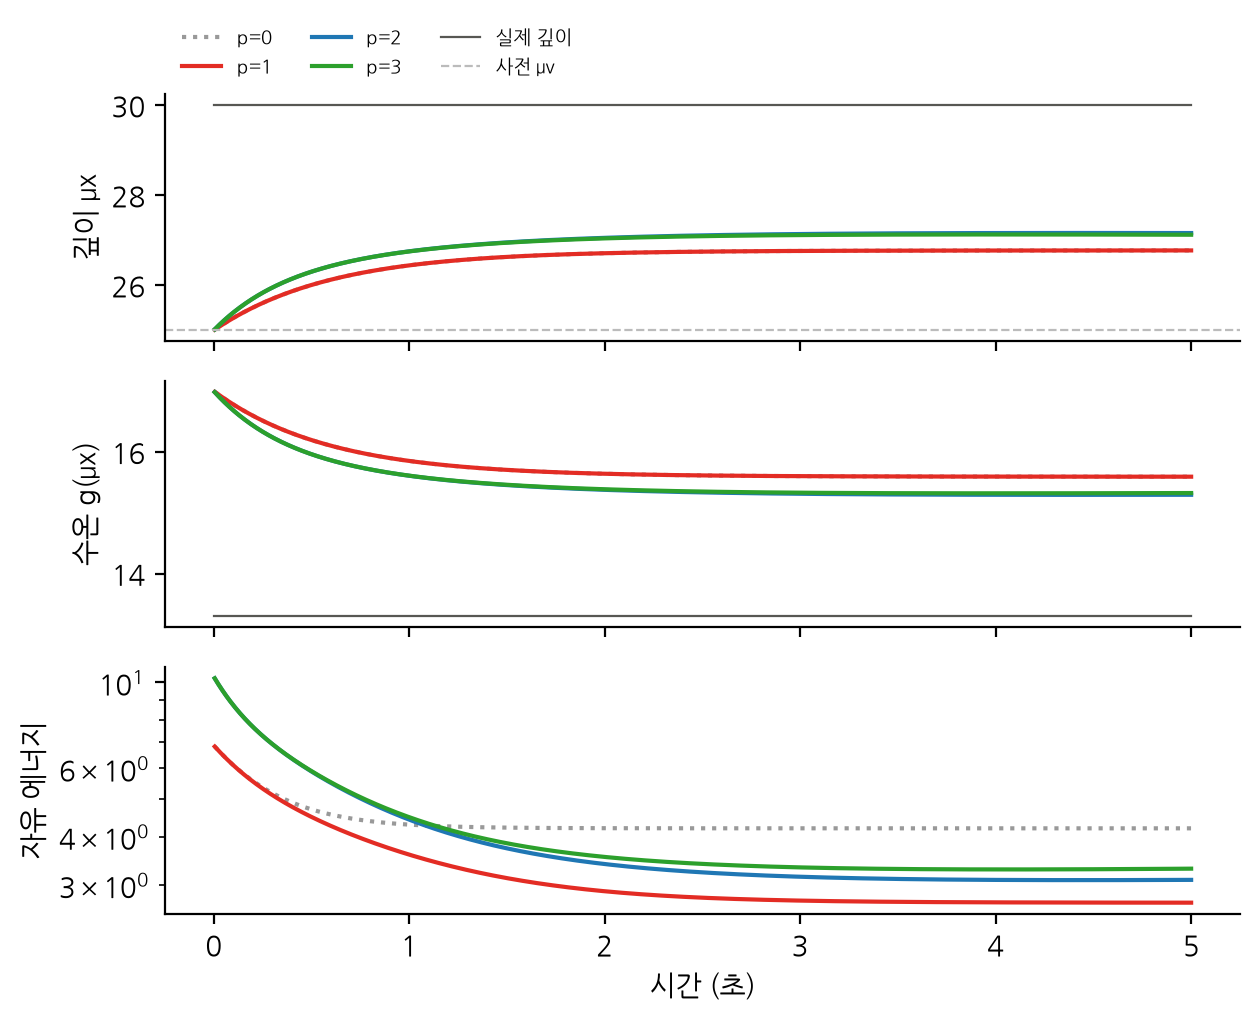

In [7]:
plot_runs(static, 25.0)

## 6. 움직이는 세계

이제 Hydar 가 실제로 움직인다. 처음 깊이는 25 이고 해류가 30 으로 데려간다. 두 경우를 본다.

- 사전이 목표 깊이와 같다(μv = 30): 사전은 「어디로 가는가」에 대한 믿음이다.
- 사전이 출발 깊이와 같다(μv = 25): 사전과 실제 목표가 어긋난다.

감각을 믿는 경우(σz² = 0.1)도 함께 비교한다.

In [8]:
def rmse(r):
    return np.sqrt(np.mean((r["mu_x"][1:] - r["x"][1:])**2))

print("사전   경우                   1초 μx (실제)       5초 μx (실제)    추적 RMSE")
dyn = {}
for mu_v in [30.0, 25.0]:
    for name, kw in [("p=0", dict(p=0)), ("p=3", dict(p=3)), ("p=3 감각 신뢰", dict(p=3, Sigma_z=0.1))]:
        r = simulation(30.0, mu_v, 25.0, **kw)
        dyn[(mu_v, name)] = r
        k = int(1 / dt)
        print(f"{mu_v:4.0f}   {name:14s}   {r['mu_x'][k]:7.3f} ({r['x'][k]:6.3f})   "
              f"{r['mu_x'][-1]:7.3f} ({r['x'][-1]:6.3f})   {rmse(r):7.3f}")

사전   경우                   1초 μx (실제)       5초 μx (실제)    추적 RMSE


  30   p=0               29.305 (28.165)    29.971 (29.967)     1.296
  30   p=3               29.129 (28.165)    29.966 (29.967)     1.217
  30   p=3 감각 신뢰         28.152 (28.165)    29.974 (29.967)     0.517
  25   p=0               25.691 (28.165)    26.752 (29.967)     2.856
  25   p=3               25.852 (28.165)    27.101 (29.967)     2.590
  25   p=3 감각 신뢰         27.525 (28.165)    29.220 (29.967)     0.686


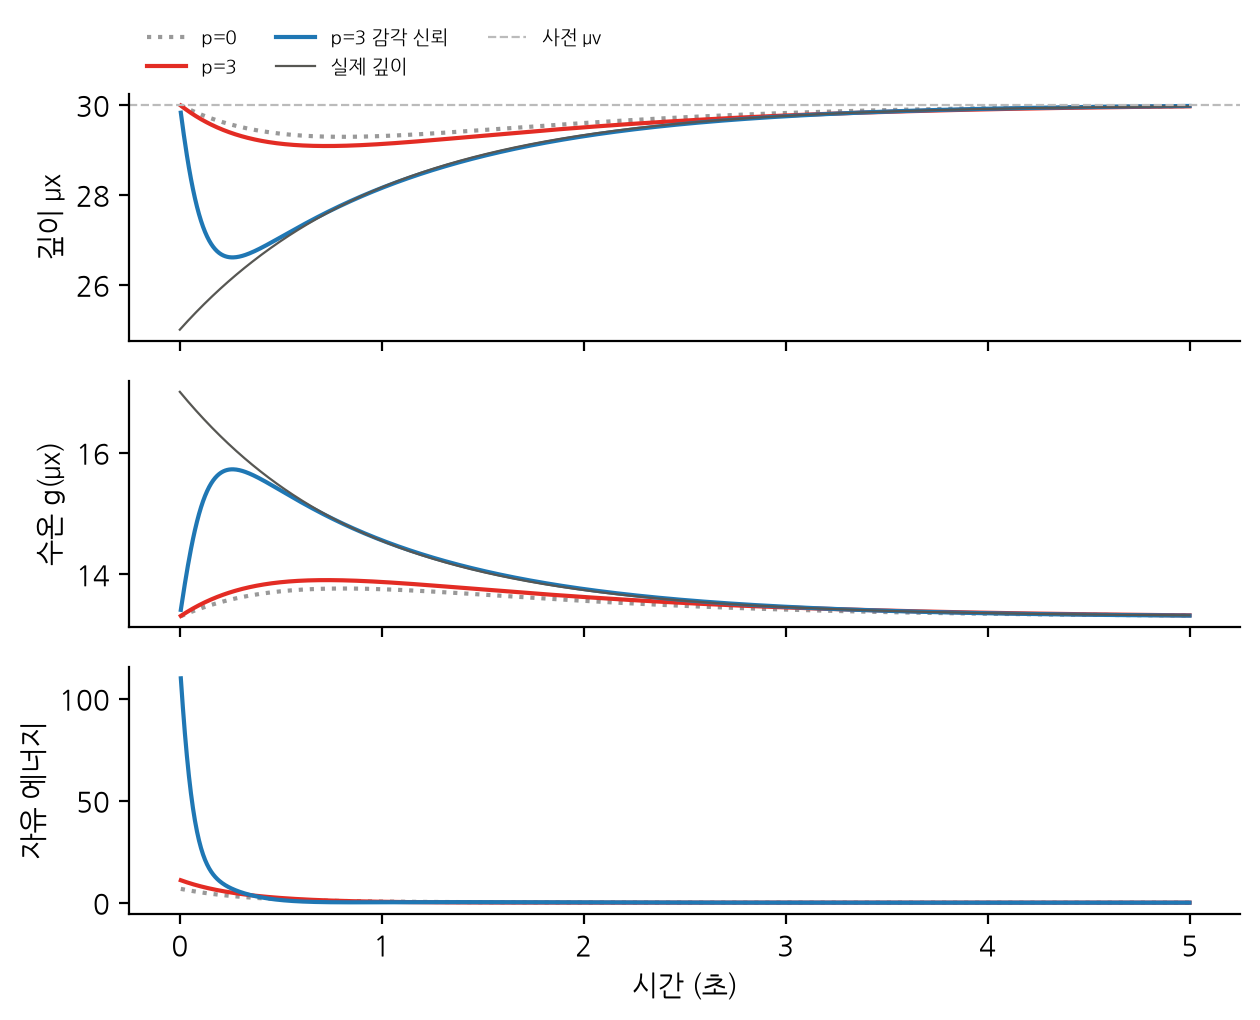

In [9]:
plot_runs({"p=0": dyn[(30.0, "p=0")], "p=3": dyn[(30.0, "p=3")],
           "p=3 감각 신뢰": dyn[(30.0, "p=3 감각 신뢰")]}, 30.0, logF=False)

## 7. 유색 잡음 속 추적

같은 움직이는 세계에 분산 1, 매끄러움 1/2000 의 유색 잡음을 넣는다. 생성 모델도 s² = 1/2000 을 가정한다.

In [10]:
print("사전   p     추적 RMSE   감각만으로 읽은 깊이의 RMSE")
for mu_v in [30.0, 25.0]:
    for p in [0, 3]:
        r = simulation(30.0, mu_v, 25.0, s2_w=1/2000, s2_z=1/2000, noise="smooth", p=p)
        yd = 5 * (5 - np.log(16 / (25 - np.clip(r["y"][1:], 9.05, 24.95)) - 1))
        print(f"{mu_v:4.0f}   {p}     {rmse(r):7.3f}      {np.sqrt(np.mean((yd - r['x'][1:])**2)):7.3f}")

사전   p     추적 RMSE   감각만으로 읽은 깊이의 RMSE
  30   0       1.278        1.453
  30   3       1.195        1.453
  25   0       3.007        1.453
  25   3       2.729        1.453


## 8. 실패 조건 — 잡음의 매끄러움을 잘못 짐작한다

첫째, 실제로는 백색 잡음(분산 0.1)인데 Hydar 는 매끄러운 잡음(s² = 1/64)을 가정하고, 일반화 감각은 후진 차분으로 만든다. 고차 도함수가 잡음을 증폭한다.

둘째, 잡음 없는 세계에서 s² = 1 처럼 과하게 매끄럽다고 가정한다. 고차 오차가 위치보다 무거워진다.

In [11]:
print("일반화 감각     가정 s²     5초 μx    추적 RMSE")
with np.errstate(all="ignore"):
    for gen_y in ["exact", "extend", "backward"]:
        for s2 in [1 / 64, 1e-5]:
            r = simulation(30.0, 25.0, 25.0, Sigma_w=0.1, Sigma_z=0.1, s2_w=s2, s2_z=s2,
                           noise="white", p=3, gen_y=gen_y)
            print(f"{gen_y:10s}    {s2:8.2g}    {r['mu_x'][-1]:9.4g}   {rmse(r):9.4g}")

ys_w = g_gp(25.0) + np.random.default_rng(1).normal(0, np.sqrt(0.1), 4)
print()
print("백색 잡음 감각 4개:", np.round(ys_w, 3), " → 후진 차분 y′′′ =", f"{sensor_backward(ys_w, 3, 3)[3, 0]:.3g}")

일반화 감각     가정 s²     5초 μx    추적 RMSE
exact            0.016        28.71       1.082
exact            1e-05        29.26       0.662
extend           0.016        28.71       1.047
extend           1e-05        29.26      0.6619


backward         0.016        62.93       64.62
backward         1e-05        29.25      0.6619

백색 잡음 감각 4개: [17.109 17.26  17.104 16.588]  → 후진 차분 y′′′ = -4.43e+05


In [12]:
d = np.diag(inv(np.kron(temporalC(3, 1.0), 1.0)))
print("s²=1 일 때 Π̃ 대각:", np.round(d, 3))
r_bad = simulation(30.0, 25.0, 25.0, s2_w=1.0, s2_z=1.0, p=3)
r_ok = simulation(30.0, 25.0, 25.0, p=3)
k = np.argmin(r_bad["mu_x"][1:int(1 / dt)]) + 1
print(f"s²=1   : 처음 1초 안의 최솟값 μx = {r_bad['mu_x'][k]:.3f} (t={t[k]:.3f}s), 5초 μx = {r_bad['mu_x'][-1]:.3f}")
print(f"s²=1/64: 처음 1초 안의 최솟값 μx = {r_ok['mu_x'][1:int(1 / dt)].min():.3f}, 5초 μx = {r_ok['mu_x'][-1]:.3f}")
print(f"실제 깊이는 25 에서 출발해 처음부터 깊어진다 (속도 {f_gp(25.0, 30.0):+.1f})")

s²=1 일 때 Π̃ 대각: [1.5   5.    2.    1.333]
s²=1   : 처음 1초 안의 최솟값 μx = 24.625 (t=0.235s), 5초 μx = 26.778
s²=1/64: 처음 1초 안의 최솟값 μx = 25.000, 5초 μx = 27.101
실제 깊이는 25 에서 출발해 처음부터 깊어진다 (속도 +5.0)


## 결론

- 일반화 정밀도는 매끄러움 s² 로 고차 오차의 무게를 정한다. 매끄러울수록 고차 정보를 많이 쓰고, 백색 잡음이면 위치만 쓴다.
- 정적인 세계에서 p = 1 은 p = 0 과 같은 답을 내고, 더 높은 차수는 감각 쪽으로 조금 더 간다.
- 움직이는 세계에서 사전은 「지금 어디에 있는가」가 아니라 「어디로 가는가」에 대한 믿음이 된다.
- 일반화 좌표는 움직이는 대상을 더 잘 쫓는다.
- 잡음의 매끄러움을 잘못 짐작하면 고차 오차가 추론을 망친다. 백색 잡음에 후진 차분을 쓰면 고차 감각이 폭발하고, s² 를 너무 크게 잡으면 속도를 먼저 맞추려다 위치가 반대로 움직인다.